# Mobile Price predictor

## Initialise

In [57]:
!pip install kagglehub
!pip install sweetviz

In [58]:
import pandas as pd
import numpy as np
import kagglehub
from pathlib import Path
import os,re 

In [59]:
path = kagglehub.dataset_download("abhishekgupta56447/flipkart-mobile-phones-dataset")
path = Path(path)
os.listdir(path)

['Flipkart Phone Data.csv']

In [60]:
df = pd.read_csv(path / 'Flipkart Phone Data.csv')

In [61]:
df

,Product_Name,Rating,Number_of_Ratings,Number_of_Review,Display_Details,Camera_Details,Battery_Details,Processor_Details,Warranty_Details,Selling_Price,Original_Price,Discount,RAM,ROM,Expandable_Storage
0,"Acer Super ZX 5G (Lunar Blue, 128 GB)",4.1,172,13,17.02 cm (6.7 inch) Display,64MP Rear Camera,5000 mAh Battery,NaN,1 Year Manufacturer,"â‚¹14,499","â‚¹23,999",39% off,4 GB RAM,128 GB ROM,NaN
1,"Ai+ Nova 2 5G (Black, 128 GB)",4.2,"3,818",235,17.13 cm (6.745 inch) HD+ Display,50MP Rear Camera | 8MP Front Camera,6000 mAh Battery,T8200 Processor,1 Year Warranty on Handset and 6 Months Warran...,"â‚¹13,999","â‚¹14,999",6% off,6 GB RAM,128 GB ROM,Expandable Upto 1 TB
2,"Ai+ Nova 2 5G (Black, 64 GB)",4.4,"4,095",167,17.13 cm (6.745 inch) HD+ Display,50MP Rear Camera | 8MP Front Camera,6000 mAh Battery,T8200 Processor,1 Year Warranty on Handset and 6 Months Warran...,"â‚¹11,999","â‚¹13,999",14% off,4 GB RAM,64 GB ROM,Expandable Upto 1 TB
3,"Ai+ Nova 2 5G (Blue, 128 GB)",4.4,"4,095",167,17.13 cm (6.745 inch) HD+ Display,50MP Rear Camera | 8MP Front Camera,6000 mAh Battery,T8200 Processor,1 Year Warranty on Handset and 6 Months Warran...,"â‚¹12,999","â‚¹17,499",25% off,4 GB RAM,128 GB ROM,Expandable Upto 1 TB
4,"Ai+ Nova 2 5G (Blue, 128 GB)",4.2,"3,818",235,17.13 cm (6.745 inch) HD+ Display,50MP Rear Camera | 8MP Front Camera,6000 mAh Battery,T8200 Processor,1 Year Warranty on Handset and 6 Months Warran...,"â‚¹13,999","â‚¹14,999",6% off,6 GB RAM,128 GB ROM,Expandable Upto 1 TB
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785,"vivo Y21 5G (Midnight Blue, 128 GB)",4.6,81,5,17.12 cm (6.74 inch) Full HD Display,50MP + 0.08MP | 5MP Front Camera,6500 mAh Li-ion Battery,Dimensity 6300 Processor,1 Year Manufacturer Warranty for Device and 6 ...,"â‚¹23,999","â‚¹35,999",33% off,6 GB RAM,128 GB ROM,Expandable Upto 2 TB
786,"vivo Y21 5G (Mystic Blue, 128 GB)",4.1,98,7,17.12 cm (6.74 inch) Full HD Display,50MP + 0.08MP | 5MP Front Camera,6500 mAh Li-ion Battery,Dimensity 6300 Processor,1 Year Manufacturer Warranty for Device and 6 ...,"â‚¹20,999","â‚¹49,999",58% off,4 GB RAM,128 GB ROM,Expandable Upto 2 TB
787,"vivo Y21 5G (Mystic Blue, 128 GB)",4.6,81,5,17.12 cm (6.74 inch) Full HD Display,50MP + 0.08MP | 5MP Front Camera,6500 mAh Li-ion Battery,Dimensity 6300 Processor,1 Year Manufacturer Warranty for Device and 6 ...,"â‚¹23,999","â‚¹54,999",56% off,6 GB RAM,128 GB ROM,Expandable Upto 2 TB
788,"vivo Y21 5G (Straw Gold, 128 GB)",4.1,98,7,17.12 cm (6.74 inch) Full HD Display,50MP + 0.08MP | 5MP Front Camera,6500 mAh Li-ion Battery,Dimensity 6300 Processor,1 Year Manufacturer Warranty for Device and 6 ...,"â‚¹20,999","â‚¹49,999",58% off,4 GB RAM,128 GB ROM,Expandable Upto 2 TB


In [62]:
print(df.shape)

(790, 15)


In [63]:
df.dtypes

Product_Name              str
Rating                float64
Number_of_Ratings         str
Number_of_Review          str
Display_Details           str
Camera_Details            str
Battery_Details           str
Processor_Details         str
Warranty_Details          str
Selling_Price             str
Original_Price            str
Discount                  str
RAM                       str
ROM                       str
Expandable_Storage        str
dtype: object

In [64]:
df.duplicated().sum()

np.int64(0)

## Data Cleaning & Integrity

In [65]:
df1 = df


In [66]:

def convert_to_MB(value):
    if isinstance(value, str):
        v  = float(re.search(r"\d+", value).group())
        if "GB" in value:
            return float(v) * 1024
        elif "MB" in value:
            return float(v)
    return np.nan

In [67]:
### Cleaning Display details
d = df1['Display_Details'].str.extract("^(?P<size>\d+.?(\d+)?)\s*cm\s*\((?P<size_inch>\d+.?(\d+)?)\s*inch\)\s*(?P<tech>.*?)\sDisplay$")
d = d[['size', "tech"]].rename(columns={"size": "display_size", "tech": "display_tech"})
df = df1.join(d)

### Camera_Details
d = df["Camera_Details"].str.split("|", expand=True)
d.rename(columns={1:"front_camera"}, inplace=True)
front = d[["front_camera"]]
rear = d[0].str.split("+",expand=True)
for x in rear.columns:
    rear[x] = rear[x].str.extract("(\d+\.?\d*)").astype(float)


rear.columns = "rear_" + rear.columns.astype(str)
df["front_camera"] = front["front_camera"].str.extract("(\d+\.?\d*)").astype(float)
df = df.join(rear)

## Battery Details
df["Battery_Details"] = df["Battery_Details"].str.extract("(\d+\.?\d*)")

## Warranty_Details
d = df["Warranty_Details"].str.replace(r"\W|\s", "", regex=True).str.lower()
d = pd.DataFrame(d.unique())
number_map = {"one1": "1","one": "1", "two":"2", "three":"3", "four":"4", "five":"5", "six":"6", "seven": "7", "eight":"8" ,"nine":"9"}
for x,y in number_map.items():
    d[0] = d[0].str.replace(x,y)
d = d[0].str.extract("(?P<warantyperiod>\d+)\s*(?P<mult>(?:years?|yrs?|months?|mon(?:th)?s?))", expand=True)
mult_map = {"year": 12, "years": 12, "yr": 12, "yrs": 12, "month": 1, "months": 1, "mon": 1, "mons": 1}
d["mult"] = d["mult"].map(mult_map)
d["warantyperiod"] = d["warantyperiod"].astype(float) * d["mult"]
df = df.join(d[["warantyperiod"]])  

## Selling_Price
df["Selling_Price"] = df["Selling_Price"].str.replace(r"\D", "", regex=True).astype(float)

## Original_Price
df["Original_Price"] = df["Original_Price"].str.replace(r"\D", "", regex=True).astype(float)


## Discount
df["Discount"] = df["Discount"].str.replace(r"\D", "", regex=True).astype(float)

##RAM AND ROM
df["RAM"] = df["RAM"].apply(convert_to_MB)
df["ROM"] = df["ROM"].apply(convert_to_MB)
df["Expandable_Storage"] = df["Expandable_Storage"].apply(convert_to_MB)

df.drop(columns=['Display_Details' , "Camera_Details", "Warranty_Details"], inplace=True)


In [68]:
df = df[['Product_Name', 'Rating', 'Number_of_Ratings', 'Number_of_Review',
       'Battery_Details', 'Processor_Details', 'Selling_Price',
       'Original_Price', 'Discount', 'RAM', 'ROM', 'Expandable_Storage',
       'display_size', 'display_tech', 'front_camera', 'rear_0', 'rear_1',
       'rear_2', 'rear_3', 'warantyperiod']]

df

,Product_Name,Rating,Number_of_Ratings,Number_of_Review,Battery_Details,Processor_Details,Selling_Price,Original_Price,Discount,RAM,ROM,Expandable_Storage,display_size,display_tech,front_camera,rear_0,rear_1,rear_2,rear_3,warantyperiod
0,"Acer Super ZX 5G (Lunar Blue, 128 GB)",4.1,172,13,5000,NaN,14499.0,23999.0,39.0,4096.0,131072.0,NaN,17.02,,NaN,64.0,NaN,NaN,NaN,12.0
1,"Ai+ Nova 2 5G (Black, 128 GB)",4.2,"3,818",235,6000,T8200 Processor,13999.0,14999.0,6.0,6144.0,131072.0,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,12.0
2,"Ai+ Nova 2 5G (Black, 64 GB)",4.4,"4,095",167,6000,T8200 Processor,11999.0,13999.0,14.0,4096.0,65536.0,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,12.0
3,"Ai+ Nova 2 5G (Blue, 128 GB)",4.4,"4,095",167,6000,T8200 Processor,12999.0,17499.0,25.0,4096.0,131072.0,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,NaN
4,"Ai+ Nova 2 5G (Blue, 128 GB)",4.2,"3,818",235,6000,T8200 Processor,13999.0,14999.0,6.0,6144.0,131072.0,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785,"vivo Y21 5G (Midnight Blue, 128 GB)",4.6,81,5,6500,Dimensity 6300 Processor,23999.0,35999.0,33.0,6144.0,131072.0,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN
786,"vivo Y21 5G (Mystic Blue, 128 GB)",4.1,98,7,6500,Dimensity 6300 Processor,20999.0,49999.0,58.0,4096.0,131072.0,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN
787,"vivo Y21 5G (Mystic Blue, 128 GB)",4.6,81,5,6500,Dimensity 6300 Processor,23999.0,54999.0,56.0,6144.0,131072.0,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN
788,"vivo Y21 5G (Straw Gold, 128 GB)",4.1,98,7,6500,Dimensity 6300 Processor,20999.0,49999.0,58.0,4096.0,131072.0,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN


## Handling Missing values

In [69]:
df.isna().sum()


Product_Name            0
Rating                  0
Number_of_Ratings       0
Number_of_Review        0
Battery_Details        27
Processor_Details     206
Selling_Price          11
Original_Price         74
Discount               84
RAM                    33
ROM                     8
Expandable_Storage    682
display_size            9
display_tech            9
front_camera          223
rear_0                 29
rear_1                393
rear_2                660
rear_3                777
warantyperiod         706
dtype: int64

In [70]:
print(df[df['Battery_Details'].isnull()]['Product_Name'].str.split("(", expand=True)[0].value_counts())
## This is of type MAR we can use KNN or other imputation technique but a simple average is used to immpute
df['base_model'] = df['Product_Name'].str.split(r'\s*\(').str[0].str.strip()

# 2. Define your battery capacity dictionary based on the base model
battery_specs = {
    'Apple iPhone 15': 3349,
    'Apple iPhone 16': 3561,
    'Apple iPhone 16 Plus': 4674,
    'Apple iPhone 17': 3692,
    'Apple iPhone 17 Pro': 4252,
    'Apple iPhone 17 Pro Max': 5088,
    'Apple iPhone 17e': 4005,
    'Apple iPhone Air': 3149
}

# 3. Fill the missing battery details using the clean base model
df['Battery_Details'] = df['Battery_Details'].fillna(df['base_model'].map(battery_specs))

df


0
Apple iPhone 17             5
Apple iPhone 17 Pro         5
Apple iPhone 16 Plus        4
Apple iPhone 17 Pro Max     4
Apple iPhone 16             3
Apple iPhone 15             2
Apple iPhone 17e            2
Apple iPhone Air            2
Name: count, dtype: int64


,Product_Name,Rating,Number_of_Ratings,Number_of_Review,Battery_Details,Processor_Details,Selling_Price,Original_Price,Discount,RAM,...,Expandable_Storage,display_size,display_tech,front_camera,rear_0,rear_1,rear_2,rear_3,warantyperiod,base_model
0,"Acer Super ZX 5G (Lunar Blue, 128 GB)",4.1,172,13,5000,NaN,14499.0,23999.0,39.0,4096.0,...,NaN,17.02,,NaN,64.0,NaN,NaN,NaN,12.0,Acer Super ZX 5G
1,"Ai+ Nova 2 5G (Black, 128 GB)",4.2,"3,818",235,6000,T8200 Processor,13999.0,14999.0,6.0,6144.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,12.0,Ai+ Nova 2 5G
2,"Ai+ Nova 2 5G (Black, 64 GB)",4.4,"4,095",167,6000,T8200 Processor,11999.0,13999.0,14.0,4096.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,12.0,Ai+ Nova 2 5G
3,"Ai+ Nova 2 5G (Blue, 128 GB)",4.4,"4,095",167,6000,T8200 Processor,12999.0,17499.0,25.0,4096.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,NaN,Ai+ Nova 2 5G
4,"Ai+ Nova 2 5G (Blue, 128 GB)",4.2,"3,818",235,6000,T8200 Processor,13999.0,14999.0,6.0,6144.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,1.0,Ai+ Nova 2 5G
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785,"vivo Y21 5G (Midnight Blue, 128 GB)",4.6,81,5,6500,Dimensity 6300 Processor,23999.0,35999.0,33.0,6144.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G
786,"vivo Y21 5G (Mystic Blue, 128 GB)",4.1,98,7,6500,Dimensity 6300 Processor,20999.0,49999.0,58.0,4096.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G
787,"vivo Y21 5G (Mystic Blue, 128 GB)",4.6,81,5,6500,Dimensity 6300 Processor,23999.0,54999.0,56.0,6144.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G
788,"vivo Y21 5G (Straw Gold, 128 GB)",4.1,98,7,6500,Dimensity 6300 Processor,20999.0,49999.0,58.0,4096.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G


In [71]:
df[df['Processor_Details'].isnull()]['Product_Name'].str.split("(", expand=True)[0].value_counts()

## Missing is completely at random hence using Mode for this

df["Processor_Details"] = df["Processor_Details"].fillna(df[~df.isna()]["Processor_Details"].mode().iloc[0])
df

,Product_Name,Rating,Number_of_Ratings,Number_of_Review,Battery_Details,Processor_Details,Selling_Price,Original_Price,Discount,RAM,...,Expandable_Storage,display_size,display_tech,front_camera,rear_0,rear_1,rear_2,rear_3,warantyperiod,base_model
0,"Acer Super ZX 5G (Lunar Blue, 128 GB)",4.1,172,13,5000,Dimensity 6300 Processor,14499.0,23999.0,39.0,4096.0,...,NaN,17.02,,NaN,64.0,NaN,NaN,NaN,12.0,Acer Super ZX 5G
1,"Ai+ Nova 2 5G (Black, 128 GB)",4.2,"3,818",235,6000,T8200 Processor,13999.0,14999.0,6.0,6144.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,12.0,Ai+ Nova 2 5G
2,"Ai+ Nova 2 5G (Black, 64 GB)",4.4,"4,095",167,6000,T8200 Processor,11999.0,13999.0,14.0,4096.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,12.0,Ai+ Nova 2 5G
3,"Ai+ Nova 2 5G (Blue, 128 GB)",4.4,"4,095",167,6000,T8200 Processor,12999.0,17499.0,25.0,4096.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,NaN,Ai+ Nova 2 5G
4,"Ai+ Nova 2 5G (Blue, 128 GB)",4.2,"3,818",235,6000,T8200 Processor,13999.0,14999.0,6.0,6144.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,1.0,Ai+ Nova 2 5G
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785,"vivo Y21 5G (Midnight Blue, 128 GB)",4.6,81,5,6500,Dimensity 6300 Processor,23999.0,35999.0,33.0,6144.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G
786,"vivo Y21 5G (Mystic Blue, 128 GB)",4.1,98,7,6500,Dimensity 6300 Processor,20999.0,49999.0,58.0,4096.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G
787,"vivo Y21 5G (Mystic Blue, 128 GB)",4.6,81,5,6500,Dimensity 6300 Processor,23999.0,54999.0,56.0,6144.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G
788,"vivo Y21 5G (Straw Gold, 128 GB)",4.1,98,7,6500,Dimensity 6300 Processor,20999.0,49999.0,58.0,4096.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G


In [72]:
print(df[df['Selling_Price'].isnull()]['base_model'].value_counts())

conditions = [
    df['base_model'].str.contains('MOTOROLA Edge 60 Pro', case=False, na=False),
]
choices = [
    25999
]

## Filling motorola price and dropping others
df['Selling_Price'] = np.select(
    conditions,
    choices,
    default=df['Selling_Price']
)
df.dropna(axis=0, how="all", subset=["Selling_Price"], inplace=True)

df

base_model
MOTOROLA Edge 60 Pro    9
realme Narzo 90x 5G     1
Samsung SM b310ED       1
Name: count, dtype: int64


,Product_Name,Rating,Number_of_Ratings,Number_of_Review,Battery_Details,Processor_Details,Selling_Price,Original_Price,Discount,RAM,...,Expandable_Storage,display_size,display_tech,front_camera,rear_0,rear_1,rear_2,rear_3,warantyperiod,base_model
0,"Acer Super ZX 5G (Lunar Blue, 128 GB)",4.1,172,13,5000,Dimensity 6300 Processor,14499.0,23999.0,39.0,4096.0,...,NaN,17.02,,NaN,64.0,NaN,NaN,NaN,12.0,Acer Super ZX 5G
1,"Ai+ Nova 2 5G (Black, 128 GB)",4.2,"3,818",235,6000,T8200 Processor,13999.0,14999.0,6.0,6144.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,12.0,Ai+ Nova 2 5G
2,"Ai+ Nova 2 5G (Black, 64 GB)",4.4,"4,095",167,6000,T8200 Processor,11999.0,13999.0,14.0,4096.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,12.0,Ai+ Nova 2 5G
3,"Ai+ Nova 2 5G (Blue, 128 GB)",4.4,"4,095",167,6000,T8200 Processor,12999.0,17499.0,25.0,4096.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,NaN,Ai+ Nova 2 5G
4,"Ai+ Nova 2 5G (Blue, 128 GB)",4.2,"3,818",235,6000,T8200 Processor,13999.0,14999.0,6.0,6144.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,1.0,Ai+ Nova 2 5G
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785,"vivo Y21 5G (Midnight Blue, 128 GB)",4.6,81,5,6500,Dimensity 6300 Processor,23999.0,35999.0,33.0,6144.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G
786,"vivo Y21 5G (Mystic Blue, 128 GB)",4.1,98,7,6500,Dimensity 6300 Processor,20999.0,49999.0,58.0,4096.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G
787,"vivo Y21 5G (Mystic Blue, 128 GB)",4.6,81,5,6500,Dimensity 6300 Processor,23999.0,54999.0,56.0,6144.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G
788,"vivo Y21 5G (Straw Gold, 128 GB)",4.1,98,7,6500,Dimensity 6300 Processor,20999.0,49999.0,58.0,4096.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G


In [74]:
print(df[df['Original_Price'].isnull()]['base_model'].value_counts())

df["Original_Price"] = df["Original_Price"].fillna(df["Selling_Price"])
df["Number_of_Ratings"] = df["Number_of_Ratings"].str.extract("(\d+\.?\d*)").astype(float)
df["Number_of_Review"] = df["Number_of_Review"].str.extract("(\d+\.?\d*)").astype(float)
df

Series([], Name: count, dtype: int64)


,Product_Name,Rating,Number_of_Ratings,Number_of_Review,Battery_Details,Processor_Details,Selling_Price,Original_Price,Discount,RAM,...,Expandable_Storage,display_size,display_tech,front_camera,rear_0,rear_1,rear_2,rear_3,warantyperiod,base_model
0,"Acer Super ZX 5G (Lunar Blue, 128 GB)",4.1,172.0,13.0,5000,Dimensity 6300 Processor,14499.0,23999.0,39.0,4096.0,...,NaN,17.02,,NaN,64.0,NaN,NaN,NaN,12.0,Acer Super ZX 5G
1,"Ai+ Nova 2 5G (Black, 128 GB)",4.2,3.0,235.0,6000,T8200 Processor,13999.0,14999.0,6.0,6144.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,12.0,Ai+ Nova 2 5G
2,"Ai+ Nova 2 5G (Black, 64 GB)",4.4,4.0,167.0,6000,T8200 Processor,11999.0,13999.0,14.0,4096.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,12.0,Ai+ Nova 2 5G
3,"Ai+ Nova 2 5G (Blue, 128 GB)",4.4,4.0,167.0,6000,T8200 Processor,12999.0,17499.0,25.0,4096.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,NaN,Ai+ Nova 2 5G
4,"Ai+ Nova 2 5G (Blue, 128 GB)",4.2,3.0,235.0,6000,T8200 Processor,13999.0,14999.0,6.0,6144.0,...,NaN,17.13,HD+,8.0,50.0,NaN,NaN,NaN,1.0,Ai+ Nova 2 5G
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785,"vivo Y21 5G (Midnight Blue, 128 GB)",4.6,81.0,5.0,6500,Dimensity 6300 Processor,23999.0,35999.0,33.0,6144.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G
786,"vivo Y21 5G (Mystic Blue, 128 GB)",4.1,98.0,7.0,6500,Dimensity 6300 Processor,20999.0,49999.0,58.0,4096.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G
787,"vivo Y21 5G (Mystic Blue, 128 GB)",4.6,81.0,5.0,6500,Dimensity 6300 Processor,23999.0,54999.0,56.0,6144.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G
788,"vivo Y21 5G (Straw Gold, 128 GB)",4.1,98.0,7.0,6500,Dimensity 6300 Processor,20999.0,49999.0,58.0,4096.0,...,NaN,17.12,Full HD,5.0,50.0,0.08,NaN,NaN,NaN,vivo Y21 5G


In [75]:
print(df[df['RAM'].isnull()]['base_model'].value_counts())
ram_specs = {
    'Apple iPhone 15': 6*1024,
    'Apple iPhone 16': 8*1024,
    'Apple iPhone 16 Plus': 8*1024,
    'Apple iPhone 17': 8*1024,
    'Apple iPhone 17 Pro': 12*1024,
    'Apple iPhone 17 Pro Max': 12*1024,
    'Apple iPhone 17e': 8*1024,
    'Apple iPhone Air': 8*1024
}

# 3. Fill the missing RAM details
df['RAM'] = df['RAM'].fillna(df['base_model'].map(ram_specs))
df["RAM"] = df["RAM"].fillna(32)

base_model
Apple iPhone 17                                                                       5
Apple iPhone 17 Pro                                                                   5
Apple iPhone 16 Plus                                                                  4
Apple iPhone 17 Pro Max                                                               4
Apple iPhone 16                                                                       3
KARBONN K110i Dual Sim Keypad Phone|1000 mAh Battery|Expandable Storage Up to 32GB    3
Apple iPhone 15                                                                       2
Apple iPhone 17e                                                                      2
Apple iPhone Air                                                                      2
IAIR D12 Dual Sim Keypad Phone | 2800 mAH Battery & Big 1.88 Inch Display             1
KARBONN K9                                                                            1
Samsung Metro 313    

In [76]:
print(df[df['ROM'].isnull()]['base_model'].value_counts())

base_model
KARBONN K110i Dual Sim Keypad Phone|1000 mAh Battery|Expandable Storage Up to 32GB    3
MOTOROLA Signature                                                                    2
Apple iPhone 17 Pro                                                                   1
IAIR D12 Dual Sim Keypad Phone | 2800 mAH Battery & Big 1.88 Inch Display             1
KARBONN K9                                                                            1
Name: count, dtype: int64


In [77]:
df["Discount"] = df["Discount"].fillna(0)

# ROM
df["ROM"] = df["ROM"].fillna(0)
# Expandable_Storage
df["Expandable_Storage"] = df["Expandable_Storage"].fillna(0)
# display_size
print(df[df['display_size'].isnull()]['base_model'].value_counts())
df
df["display_size"] = df["display_size"].astype(float)
df["display_size"] = df["display_size"].fillna(df["display_size"][~df["display_size"].isna()].mean()) 

df['display_tech'] = df['display_tech'].fillna("standard").replace("", "standard")
for i in ["front_camera", "rear_0", "rear_1", "rear_2", "rear_3","warantyperiod"]:
    df[i] = df[i].astype(float).fillna(0)


df

base_model
realme P4 Lite 5G    4
REDMI A7             2
vivo X300 Pro        2
vivo V70             1
Name: count, dtype: int64


,Product_Name,Rating,Number_of_Ratings,Number_of_Review,Battery_Details,Processor_Details,Selling_Price,Original_Price,Discount,RAM,...,Expandable_Storage,display_size,display_tech,front_camera,rear_0,rear_1,rear_2,rear_3,warantyperiod,base_model
0,"Acer Super ZX 5G (Lunar Blue, 128 GB)",4.1,172.0,13.0,5000,Dimensity 6300 Processor,14499.0,23999.0,39.0,4096.0,...,0.0,17.02,standard,0.0,64.0,0.00,0.0,0.0,12.0,Acer Super ZX 5G
1,"Ai+ Nova 2 5G (Black, 128 GB)",4.2,3.0,235.0,6000,T8200 Processor,13999.0,14999.0,6.0,6144.0,...,0.0,17.13,HD+,8.0,50.0,0.00,0.0,0.0,12.0,Ai+ Nova 2 5G
2,"Ai+ Nova 2 5G (Black, 64 GB)",4.4,4.0,167.0,6000,T8200 Processor,11999.0,13999.0,14.0,4096.0,...,0.0,17.13,HD+,8.0,50.0,0.00,0.0,0.0,12.0,Ai+ Nova 2 5G
3,"Ai+ Nova 2 5G (Blue, 128 GB)",4.4,4.0,167.0,6000,T8200 Processor,12999.0,17499.0,25.0,4096.0,...,0.0,17.13,HD+,8.0,50.0,0.00,0.0,0.0,0.0,Ai+ Nova 2 5G
4,"Ai+ Nova 2 5G (Blue, 128 GB)",4.2,3.0,235.0,6000,T8200 Processor,13999.0,14999.0,6.0,6144.0,...,0.0,17.13,HD+,8.0,50.0,0.00,0.0,0.0,1.0,Ai+ Nova 2 5G
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785,"vivo Y21 5G (Midnight Blue, 128 GB)",4.6,81.0,5.0,6500,Dimensity 6300 Processor,23999.0,35999.0,33.0,6144.0,...,0.0,17.12,Full HD,5.0,50.0,0.08,0.0,0.0,0.0,vivo Y21 5G
786,"vivo Y21 5G (Mystic Blue, 128 GB)",4.1,98.0,7.0,6500,Dimensity 6300 Processor,20999.0,49999.0,58.0,4096.0,...,0.0,17.12,Full HD,5.0,50.0,0.08,0.0,0.0,0.0,vivo Y21 5G
787,"vivo Y21 5G (Mystic Blue, 128 GB)",4.6,81.0,5.0,6500,Dimensity 6300 Processor,23999.0,54999.0,56.0,6144.0,...,0.0,17.12,Full HD,5.0,50.0,0.08,0.0,0.0,0.0,vivo Y21 5G
788,"vivo Y21 5G (Straw Gold, 128 GB)",4.1,98.0,7.0,6500,Dimensity 6300 Processor,20999.0,49999.0,58.0,4096.0,...,0.0,17.12,Full HD,5.0,50.0,0.08,0.0,0.0,0.0,vivo Y21 5G


## Univariate Analysis


In [78]:
import seaborn as sns
import matplotlib.pyplot as plt

In [79]:
df.columns

Index(['Product_Name', 'Rating', 'Number_of_Ratings', 'Number_of_Review',
       'Battery_Details', 'Processor_Details', 'Selling_Price',
       'Original_Price', 'Discount', 'RAM', 'ROM', 'Expandable_Storage',
       'display_size', 'display_tech', 'front_camera', 'rear_0', 'rear_1',
       'rear_2', 'rear_3', 'warantyperiod', 'base_model'],
      dtype='str')

Text(0.5, 1.0, 'No of Reviews Vs Selling Price')

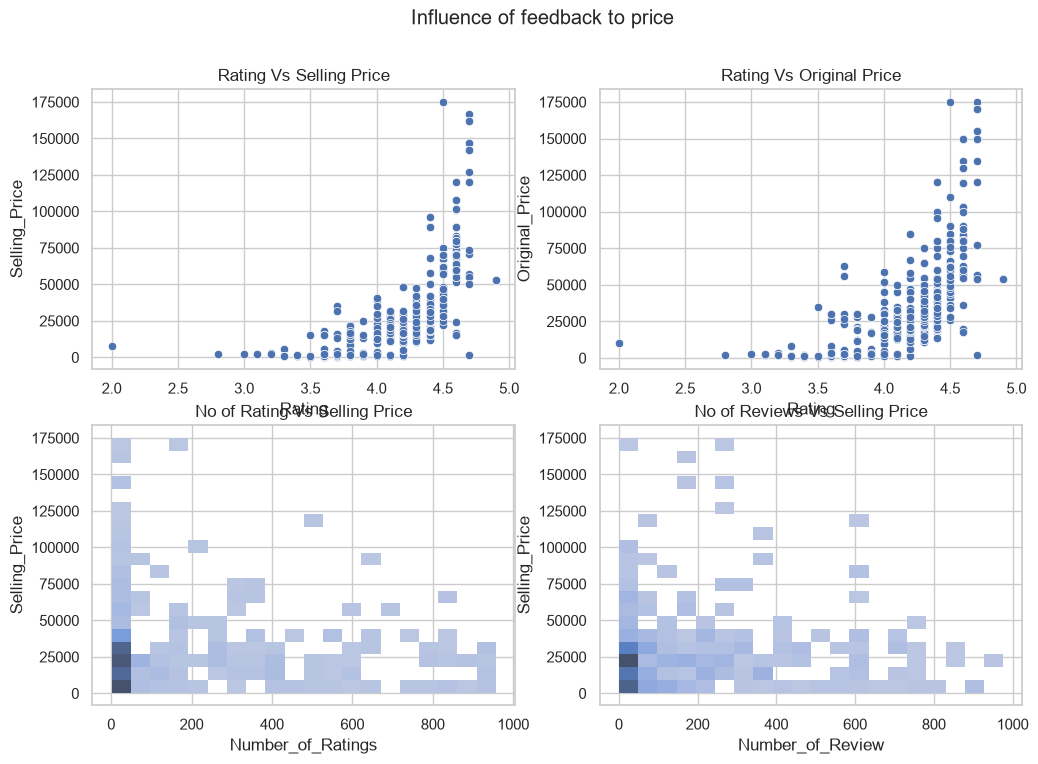

In [119]:
plt.figure(figsize=(12, 8))
plt.suptitle("Influence of feedback to price")
plt.subplot(2, 2, 1)
sns.scatterplot(df, x='Rating', y='Selling_Price',)
plt.title("Rating Vs Selling Price")
plt.subplot(2, 2, 2)
sns.scatterplot(df, x='Rating', y='Original_Price',)
plt.title("Rating Vs Original Price")
plt.subplot(2, 2, 3)
sns.histplot(df, x='Number_of_Ratings', y='Selling_Price', kde=True, bins=20)
plt.title("No of Rating Vs Selling Price")
plt.subplot(2, 2, 4)
sns.histplot(df, x='Number_of_Review', y='Selling_Price',bins= 20 )
plt.title("No of Reviews Vs Selling Price")

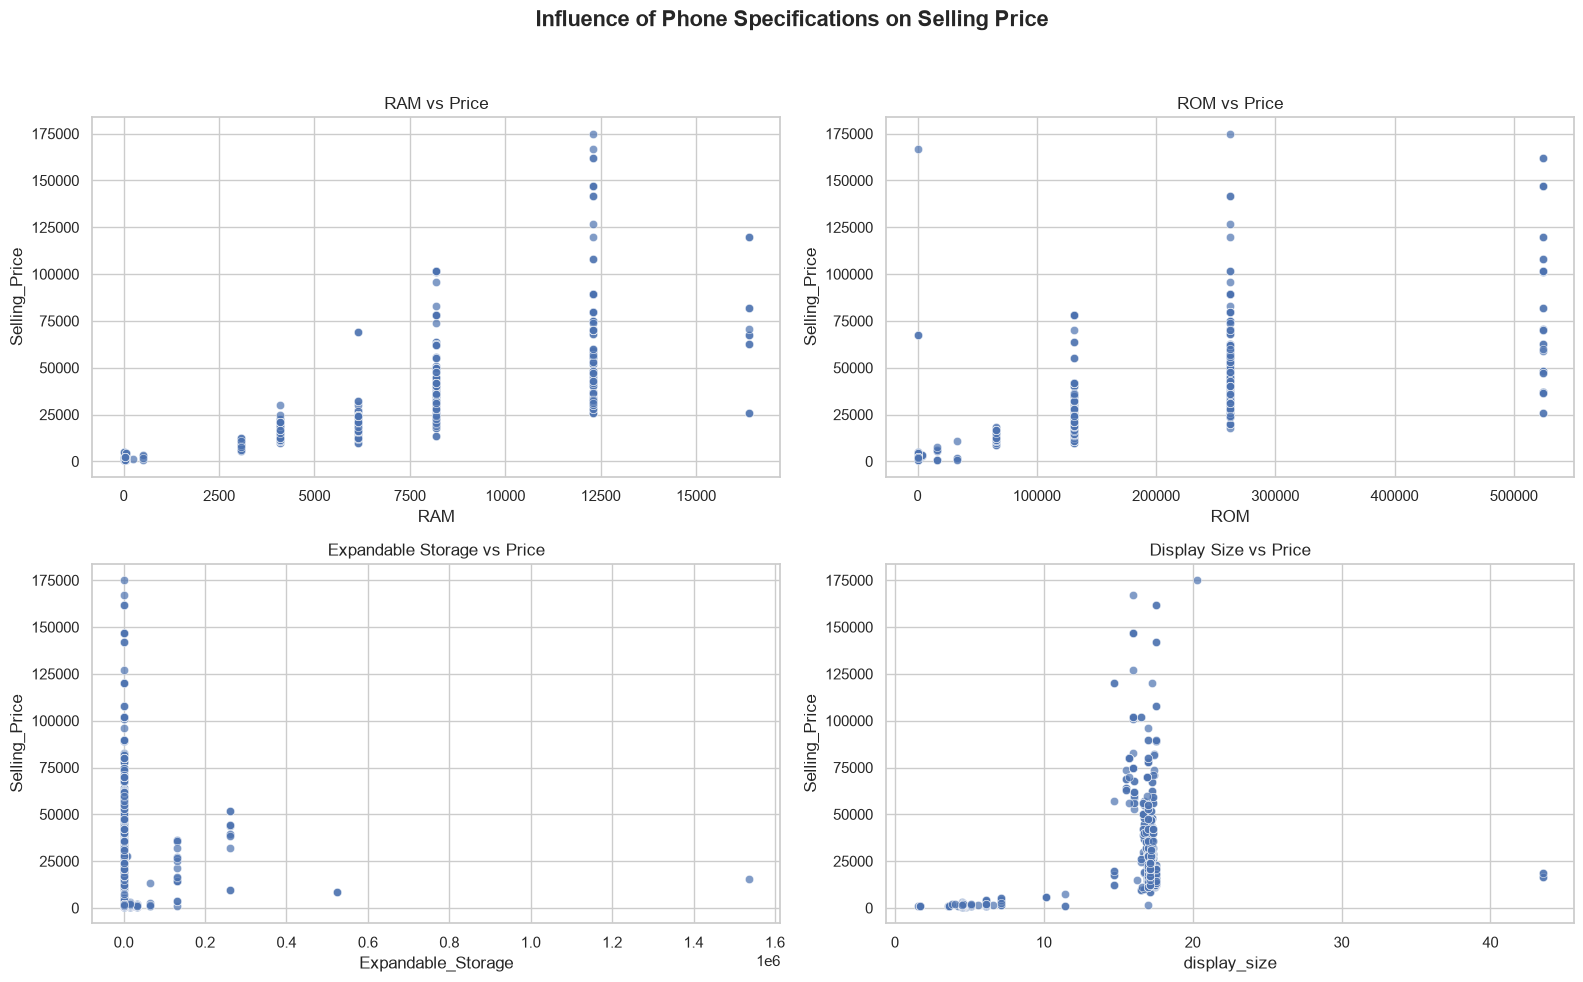

In [117]:
df['Battery_Details'] = df['Battery_Details'].astype(float).astype(int).fillna('Unknown').astype(str)
df['Processor_Details'] = df['Processor_Details'].fillna('Unknown').astype(str)

sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 10))
plt.suptitle("Influence of Phone Specifications on Selling Price", fontsize=16, fontweight="bold", y=0.98)

plt.subplot(2, 2, 1)

# --- Subplot 3: RAM vs Price ---
sns.scatterplot(data=df, x='RAM', y='Selling_Price', alpha=0.7)
plt.title("RAM vs Price")

# --- Subplot 4: ROM vs Price ---
plt.subplot(2, 2, 2)
sns.scatterplot(data=df, x='ROM', y='Selling_Price', alpha=0.7)
plt.title("ROM vs Price")

# --- Subplot 5: Expandable Storage vs Price ---
plt.subplot(2, 2, 3)
sns.scatterplot(data=df, x='Expandable_Storage', y='Selling_Price', alpha=0.7)
plt.title("Expandable Storage vs Price")

# --- Subplot 6: Display Size vs Price ---
plt.subplot(2, 2, 4)
sns.scatterplot(data=df, x='display_size', y='Selling_Price', alpha=0.7)
plt.title("Display Size vs Price")

# 3. Adjust layout spacing and display
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

In [121]:
df.corr(numeric_only=True)

,Rating,Number_of_Ratings,Number_of_Review,Selling_Price,Original_Price,Discount,RAM,ROM,Expandable_Storage,display_size,front_camera,rear_0,rear_1,rear_2,rear_3,warantyperiod
Rating,1.000000,-0.091720,0.111939,0.641738,0.632477,-0.328262,0.705396,0.632264,-0.029311,0.574998,0.410880,0.542897,0.384027,0.279831,0.137594,0.063460
Number_of_Ratings,-0.091720,1.000000,-0.283509,-0.032000,-0.022326,0.072288,0.003467,-0.040633,0.031702,-0.018763,-0.015803,0.056129,-0.024848,0.055663,-0.040526,-0.008364
Number_of_Review,0.111939,-0.283509,1.000000,0.028273,0.012596,-0.064429,0.046835,0.048740,-0.046119,-0.026706,0.025157,0.063181,0.051870,0.013032,0.071533,-0.038855
Selling_Price,0.641738,-0.032000,0.028273,1.000000,0.964467,-0.294057,0.746374,0.725580,-0.045886,0.429908,0.407551,0.552098,0.592234,0.542630,0.249434,0.162442
Original_Price,0.632477,-0.022326,0.012596,0.964467,1.000000,-0.098123,0.760018,0.726973,-0.057190,0.463204,0.451054,0.592414,0.619588,0.546618,0.294193,0.122422
Discount,-0.328262,0.072288,-0.064429,-0.294057,-0.098123,1.000000,-0.304724,-0.268760,-0.037837,-0.230787,-0.140564,-0.210558,-0.106287,-0.078226,0.002933,-0.085317
RAM,0.705396,0.003467,0.046835,0.746374,0.760018,-0.304724,1.000000,0.837454,-0.043687,0.679826,0.631147,0.660023,0.555874,0.403461,0.173185,-0.002417
ROM,0.632264,-0.040633,0.048740,0.725580,0.726973,-0.268760,0.837454,1.000000,-0.033674,0.547063,0.557882,0.543026,0.540563,0.415290,0.195507,0.048547
Expandable_Storage,-0.029311,0.031702,-0.046119,-0.045886,-0.057190,-0.037837,-0.043687,-0.033674,1.000000,-0.004967,-0.104995,-0.044781,-0.079013,-0.045260,-0.021201,-0.030796
display_size,0.574998,-0.018763,-0.026706,0.429908,0.463204,-0.230787,0.679826,0.547063,-0.004967,1.000000,0.379743,0.610935,0.222322,0.097427,0.062405,-0.010176


<Axes: >

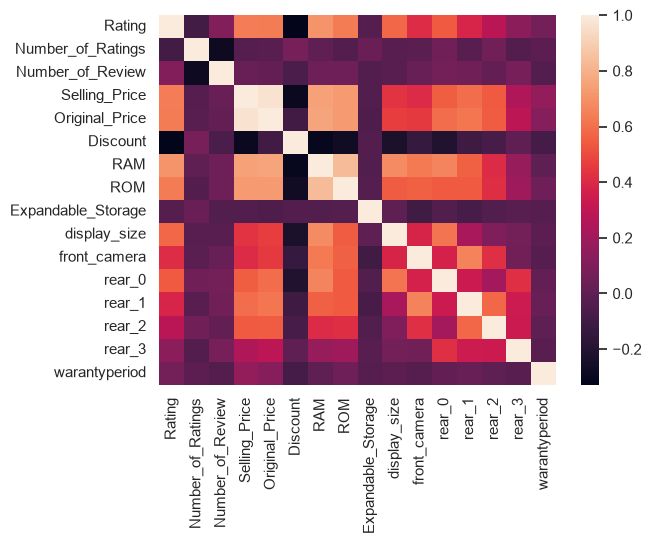

In [122]:
sns.heatmap(df.corr(numeric_only=True))

## Inference from heat map

1. RAM and ROM is the most influnces factor on selling price
2. Then the rating then the Display size and camera influnces the selling price
3. Number_of_Ratings, Number_of_Review has very weak or neutral correlation with hardware specs and pricing
